# Fingerprint by Design
### Predicting, tracing and stabilising the RF fingerprint of an open-source SKY130 transmitter, before any silicon exists

Submission to the IEEE SSCS Open-Source Ecosystem "Code-a-Chip" Travel Grant Awards at ISSCC 2027

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/byungkim113/sscs-ose-code-a-chip.github.io/blob/isscc27-fingerprint-by-design/ISSCC27/submitted_notebooks/fingerprint_by_design/fingerprint_by_design.ipynb)

SPDX-License-Identifier: Apache-2.0

| Name | Affiliation | IEEE Member | SSCS Member | Email |
|---|---|---|---|---|
| Byung Kim (Leader) | United States Air Force Academy | No | No | c29byung.kim@afacademy.af.edu |
| Yucheng Wang (Representative) | University of Wisconsin-Madison | No | No | ywang3574@wisc.edu |

## Introduction

Every radio transmitter is slightly imperfect. No two transistors on a chip come out of the factory exactly alike, so two
chips made from the **same design** send slightly different signals for the same data. A receiver can learn these tiny
differences and recognise which physical chip sent a signal. This is called an **RF fingerprint**, and it is used to
authenticate IoT devices, to spot counterfeit hardware, and, from the other side, it is a privacy concern.

Most RF-fingerprinting work studies devices **after** they are built: people record real devices and train a
classifier on whatever differences happen to be there. If the fingerprint drifts when the battery runs down or the
device warms up, they find out in the field. Design-time studies exist: RF-PUF [1], for example, used simulated process
variation in transmitter circuits to show that a receiver can learn device-specific signatures. What has been missing
is an open, reproducible way for a designer to take one transmitter from schematic to verified layout and ask, with
transistor-level Monte Carlo, where its fingerprint comes from, which design choices move it, and what makes it drift.

This notebook asks a different question:

> **Can a circuit designer predict, explain and control a transmitter's fingerprint at design time, using only the open
> PDK, before any silicon exists?**

To answer it we designed a complete transmitter core in the open-source **SkyWater SKY130** process, verified its layout
(DRC, LVS, parasitic extraction), and then simulated hundreds of "virtual chips" of that one design, each with its own
random transistor mismatch from the PDK's Monte Carlo models. A software receiver then tries to tell the chips apart.

What is new here is that combination, all with open tools: a stage-by-stage trace of where the fingerprint is
created, controlled design experiments that move it (PA linearity, DAC sizing, an on-chip regulator), drift tests
across supply and temperature, and tests whose predictions were written down before they ran. Along the way we found
what actually breaks the fingerprint in this setup (it is not what we expected) and how a standard circuit block, an
**on-chip voltage regulator**, makes it stable. We also report what did **not** work.

## Results at a glance

| Question | Answer (transistor-level simulations of the laid-out design; known 128-sample frame, see Section 2) |
|---|---|
| Can chips of one identical design be told apart? | **Yes, with a 92 us burst** (18 repetitions of the frame, averaged). 16 chips: 100% at 30 dB SNR; 64 chips: still 100% at 30 dB. Same-design impostor equal error rate is 0% at 30 dB and 7.37% at 20 dB. From a single 128-sample frame: 89% (16 chips) and 73% (64 chips) at 30 dB. |
| Where does the fingerprint come from? | Mismatch in the **DACs and mixers**, then about **7.24x greater chip-specific energy after the power amplifier (PA)**, including the PA's own mismatch. The output buffer adds very little; LO quadrature errors add almost nothing. |
| Can a design choice change it? | **Yes.** A more linear PA shrinks the fingerprint to 0.62x. Bigger DAC transistors halve the mismatch at the mixer but barely change the final fingerprint, because the PA dominates. |
| Does it survive the layout? | **Yes.** After parasitic extraction the fingerprint is 0.99x its schematic size. |
| What breaks it? | **Supply voltage more than temperature**, in this setup (external LO, known repeated frame, simulated devices). A 10% drop in supply voltage collapses identification from 100% to 34%. Cold plus low supply: 7%. |
| Can design-time knowledge fix that? | **Mostly.** A drift model learned only from simulations of *other* chips at *wrong* process corners restores 100% at 30 dB across +-10% supply on chips it has never seen (it passed our strict pre-registered rule on 2 of 3 chip sets), and recovers 92% of the loss under combined temperature and supply drift. |
| Can a design change fix it at the source? | **Yes.** We added an on-chip LDO regulator (bandgap reference + 5 V pass device). With it, identification stays at **100% across the whole +-10% supply range** and at 88-94% under combined temperature and supply drift. |
| What is still open? | Fingerprints work on a **known sequence** (like a packet preamble). Identifying chips from **arbitrary data** works at room conditions (93%) but not under temperature drift, even with the regulator. |

The main tests were **pre-registered**: the prediction and the pass/fail rule were written into the project log
*before* the simulations ran. Several predictions failed, and we report them as failures. Analyses chosen after seeing
data are labelled **post hoc** or **exploratory** where they appear (for example the 70/30 split of the mismatch in
Result 2, drift model B v2 on the first chip set, the burst-length analysis in Result 1, and the extra regulator
start-up ramps).

## Notebook overview

![workflow](images/workflow.png)

1. **The chip**: what we built in SKY130 (analog core, regulator and digital front end) and how it was verified.
2. **How we measure a fingerprint**: virtual chips, the receiver, and how we kept ourselves honest; then **2b, try it
   yourself**: simulate two virtual chips at transistor level from this notebook.
3. **Result 1, identification**: can we tell chips apart, and how does that scale?
4. **Result 2, origin**: which blocks create the fingerprint?
5. **Result 3, design levers**: can we make it bigger or smaller on purpose?
6. **Result 4, layout**: does it survive real wiring parasitics?
7. **Result 5, drift**: what breaks it, and can design-time models compensate?
8. **Result 6, the regulator**: fixing drift at the source with an on-chip LDO.
9. **What did not work**: arbitrary data, and where receiver-side fixes stop.
10. **Lessons for designers**, reproducibility, conclusion and future work; **Appendix A**, the layout verification correction.

### How to run this notebook

There are three levels, from seconds to days:

1. **Read and replot (default, seconds).** Every figure is recreated from the result files in `data/`, on Colab or
   locally, with only `numpy`, `matplotlib` and `gdstk` (for the layout file).
2. **Simulate it yourself (optional, about 10-20 minutes on Colab).** Section 2b installs the SKY130 PDK and ngspice and
   simulates two virtual chips plus the mismatch-free design at transistor level, then checks that your fingerprints match
   ours. Set `RUN_LIVE = True` in that cell.
3. **Reproduce everything (days).** The full study took several days of ngspice time on a laptop and about 55 GB of
   waveforms; *Reproducing the results* lists the script for every result.

In [1]:
# Setup: find the data (local checkout or Colab) and define plotting helpers
import json, os, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
try:
    import gdstk                                             # reads the layout files (GDS)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdstk"], capture_output=True)
    try:
        import gdstk
    except ImportError:                                      # e.g. no wheel for this platform
        gdstk = None
        print("gdstk is not available here: the two layout cells will show saved pictures instead")

# Where a bare runtime (e.g. Colab opened from GitHub) fetches this folder from, tried in order
SUB = "ISSCC27/submitted_notebooks/fingerprint_by_design"
SOURCES = [("https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io.git", "main", SUB),
           ("https://github.com/byungkim113/sscs-ose-code-a-chip.github.io.git", "isscc27-fingerprint-by-design", SUB),
           ("https://github.com/byungkim113/Code-A-Chip.git", "main", "notebook")]
HERE = os.path.abspath(".")
# A project-root launch also has data/, but that folder holds the older block studies.
for candidate in (HERE, os.path.join(HERE, "notebook")):
    if os.path.isfile(os.path.join(candidate, "data", "live_reference.json")):
        HERE = candidate
        break
if not os.path.isfile(os.path.join(HERE, "data", "live_reference.json")):
    for i, (url, branch, sub) in enumerate(SOURCES):
        dest = os.path.abspath(f"fbd_src{i}")
        if not os.path.isdir(dest):
            ok = subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse", "-b", branch,
                                 url, dest], capture_output=True).returncode == 0
            ok = ok and subprocess.run(["git", "-C", dest, "sparse-checkout", "set", sub], capture_output=True).returncode == 0
        if os.path.isdir(os.path.join(dest, sub, "data")):
            HERE = os.path.join(dest, sub)
            break
    else:
        raise RuntimeError("could not fetch the notebook's data folder; open the notebook from its folder instead")
os.chdir(HERE)

def load(name):
    with open(os.path.join("data", name + ".json")) as f:
        return json.load(f)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
C = {"base": "#4c72b0", "ldo": "#8a2be2", "comp": "#dd8452", "bad": "#c44e52", "good": "#55a868", "grey": "#999999"}
print("data files:", len(os.listdir("data")))

data files: 27


## 1. The chip

The design is a direct-conversion transmitter core, the part of a radio that turns digital I/Q samples into a modulated
RF signal:

![signal chain](images/signal_chain.png)

* **DACs.** Each of the I and Q channels has 31 equal current cells (a unary, "thermometer" DAC). The data bits switch
  each cell's current to one side or the other.
* **Mixers.** The DAC currents feed Gilbert switching quads that are driven by the local oscillator (LO). The I and Q
  outputs add up in a shared load.
* **LO path.** An external 200 MHz LO is buffered, split into I and Q by an RC-CR network, and squared up by inverter
  limiters (SkyWater standard cells).
* **PA and output buffer.** A differential-pair power amplifier drives source followers into a 50 ohm load.
* **Bias and supply.** An on-chip bias reference feeds every block, and an on-chip **LDO regulator** (added in
  Result 6) turns an external 3.3 V supply into the core's 1.8 V.

### Layout and verification

![layout](images/chip_layout_annotated.png)

| Check | Result |
|---|---|
| Size | 543 x 398 um (core + LDO) |
| DRC | 0 errors in Magic **and** in the official KLayout deck |
| LVS | Netgen match, 300 devices, **including device sizes** (strict property check; see the correction below) |
| Parasitic extraction | Magic, 477 devices + 1,947 parasitic capacitors; post-layout EVM 13.5% vs 14.0% in the schematic |
| Power nets | a met5 ground spine and a metal-only connectivity check (LVS alone cannot see a ground tie missing, because the substrate already joins grounds) |

Most cells were drawn with gLayout primitives or Magic's SKY130 device generator, placed and routed by our own Python
scripts. Two things the layout taught us, which later matter for the fingerprint story:

* **Parasitics can wreck the I/Q balance.** The first extracted layout had a 27.7 degree quadrature error (EVM 28%),
  because the RC-CR network is high impedance and a few femtofarads of wiring shifted its phase. Moving a capacitor's
  bottom plate to the driven node and trimming one resistor brought it to 2 degrees.
* **The regulator needs its own start-up protection.** Without it the LDO output briefly followed the 3.3 V input on
  power-up (up to 3.0 V on 1.8 V transistors). A start-up guard and a soft-start keep the **extracted layout** below
  1.95 V in every case we tested: -40, 27 and 85 C with 1, 10, 50 and 200 us supply ramps to 3.63 V (worst case
  1.933 V at 85 C with a 50 us ramp, so the margin is thin).

**Correction.** A review by co-author Yucheng Wang found that our first LVS check had passed six devices drawn at the wrong
size, including the regulator's soft-start capacitor (30 x 30 um instead of 70 x 70 um). They were fixed, and the
numbers above are for the corrected layout; Appendix A gives the details.

The layout file itself is in `gds/tx_core.gds.gz`. The cell below reads it and draws the main layers, so you can check
the layout without installing any EDA tool (open it in KLayout for full detail).

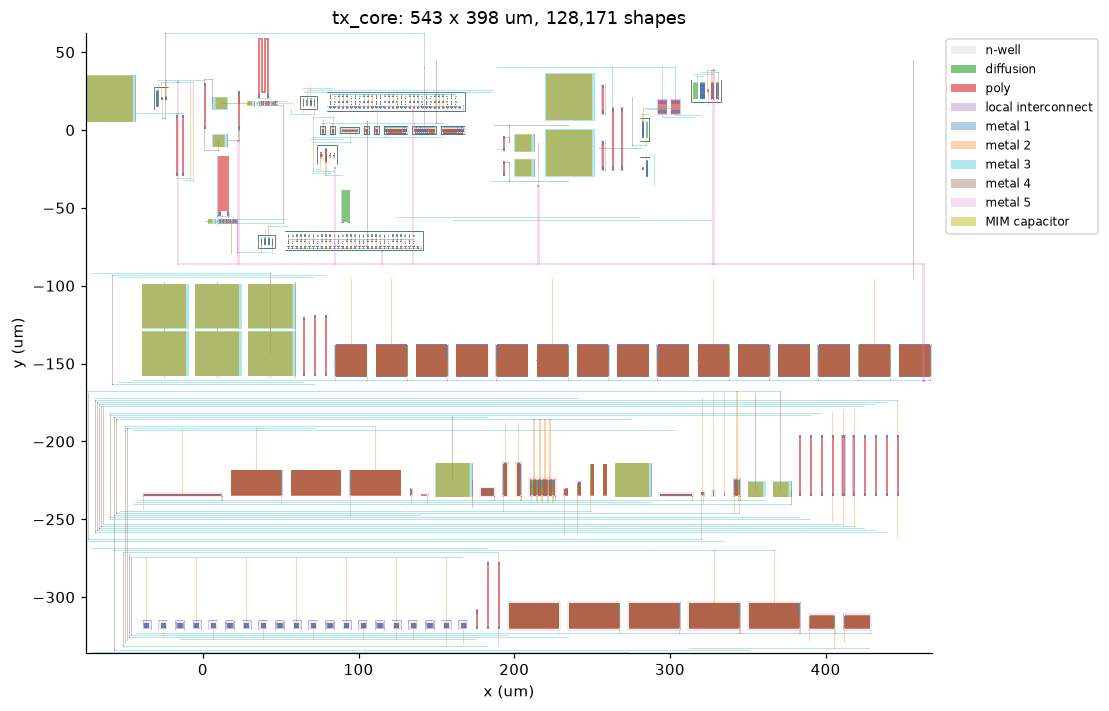

In [2]:
import gzip, shutil, tempfile
from matplotlib.collections import PolyCollection
LAYERS = [((64, 20), "n-well", "#bbbbbb", 0.25), ((65, 20), "diffusion", "#2ca02c", 0.6), ((66, 20), "poly", "#d62728", 0.6),
          ((67, 20), "local interconnect", "#9467bd", 0.35), ((68, 20), "metal 1", "#1f77b4", 0.35),
          ((69, 20), "metal 2", "#ff7f0e", 0.35), ((70, 20), "metal 3", "#17becf", 0.35), ((71, 20), "metal 4", "#8c564b", 0.35),
          ((72, 20), "metal 5", "#e377c2", 0.25), ((89, 44), "MIM capacitor", "#bcbd22", 0.5)]
def draw_gds(path, ax, layers=None, fallback=None):
    # read a gzipped GDS with gdstk, flatten it and draw the chosen layers
    if gdstk is None:
        ax.imshow(plt.imread(fallback)); ax.set_axis_off(); ax.set_title(os.path.basename(path) + " (saved picture)")
        return
    tmp = os.path.join(tempfile.gettempdir(), os.path.basename(path)[:-3])
    with gzip.open(path) as src, open(tmp, "wb") as dst:
        shutil.copyfileobj(src, dst)
    top = gdstk.read_gds(tmp).top_level()[0]
    by_layer = {}
    for p in top.get_polygons():
        by_layer.setdefault((p.layer, p.datatype), []).append(p.points)
    for key, name, col, a in LAYERS:
        if key in by_layer and (layers is None or name in layers):
            ax.add_collection(PolyCollection(by_layer[key], facecolor=col, edgecolor="none", alpha=a, label=name))
    (x0, y0), (x1, y1) = top.bounding_box()
    ax.set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal", xlabel="x (um)", ylabel="y (um)",
           title=f"{top.name}: {x1 - x0:.0f} x {y1 - y0:.0f} um, {sum(map(len, by_layer.values())):,} shapes")
    ax.grid(False)

fig, ax = plt.subplots(figsize=(10, 7.2))
draw_gds("gds/tx_core.gds.gz", ax, fallback="images/chip_layout.png")
if gdstk: ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8); plt.tight_layout(); plt.show()

### Digital front end: from 124 data pins to an SPI port

The analog core above is driven by 124 digital lines: 31 thermometer bits and their complements, for I and for Q. No
packaged chip could bring those out to pins, so we also designed the digital block that would sit in front of the core
(`digital/src/tx_frontend.v`):

* an **SPI port** (4 pins) through which a controller loads a 128-sample I/Q frame and sets a few control registers;
* a **128-word frame memory**, built as a ring of flip-flops that rotates by one word per sample: playback always reads
  samples in order, so no 128-way read multiplexer is needed (our first version had one, and it failed timing and slew
  limits because of it). The ring runs on a **gated clock** (SKY130's integrated clock-gate cell), which cut its area by
  about a quarter and its estimated power from 5.8 mW to 1.0 mW;
* a **thermometer decoder** that turns each 5-bit code into the 31 switch lines, with registered true and complement
  outputs so both change on the same clock edge, exactly as the transistor-level simulations drove the DAC.

It was taken from RTL to a routed layout with the open-source LibreLane flow (Yosys, OpenROAD, Magic, Netgen, KLayout):

| Check | Result |
|---|---|
| Size | 290 x 301 um (0.087 mm2), 4,647 standard cells including 1,482 flip-flops |
| Timing (9 corners: ss 100 C 1.60 V to ff -40 C 1.95 V) | met at a 50 MHz clock (twice the 25 MHz sample rate): setup slack at least +11.0 ns, hold slack at least +0.06 ns |
| DRC / LVS / antenna | 0 errors in Magic and KLayout, LVS clean, no antenna violations |
| Power (vectorless estimate) | 1.0 mW; worst IR drop 0.4 mV |
| Functional tests | 947 checks, 0 errors, on the RTL **and** on the final routed gate-level netlist; the main study's frame played back matches `sim/tx_full.py` exactly; 3 deliberately injected bugs are each caught |
| Remaining warnings | at the slowest corner, 4 nets driven by hold-fix delay cells have 0.77-0.88 ns edges, above the flow's 0.75 ns target (the cell library's own limit is 1.5 ns, and timing includes these edges); the gated clock's root buffer drives 16 branches against a guideline of 10 |

The front end is a separate, signed-off block: it is **not yet wired to the analog core** in one layout, and pads are
not included, so this is not a complete tape-out. It is drawn below from its GDS file (metal layers only).

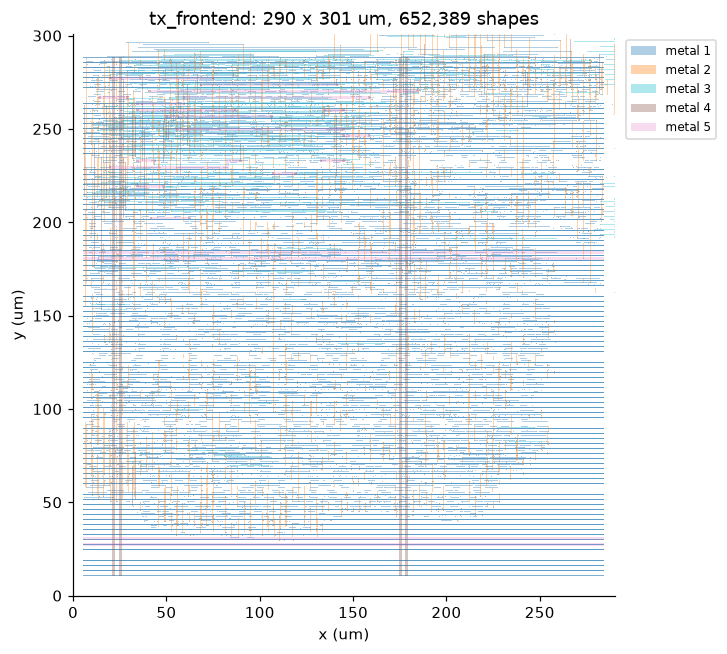

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_gds("gds/tx_frontend.gds.gz", ax, layers={"metal 1", "metal 2", "metal 3", "metal 4", "metal 5"},
         fallback="images/frontend_layout.png")
if gdstk: ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8); plt.tight_layout(); plt.show()

## 2. How we measure a fingerprint

**Virtual chips.** SKY130's transistor models include random **mismatch**: every transistor gets a slightly different
threshold voltage and size, with the spread set by its area (Pelgrom's law). Running ngspice in Monte Carlo mode with a
fixed seed gives one "virtual chip"; the same seed gives the same chip at every temperature or supply. We simulate the
whole transmitter at transistor level, for every chip.

**What the receiver sees.** Each chip transmits the same known 128-sample QPSK frame (like a packet preamble). The
receiver downconverts the RF, estimates the output level for every DAC code, and keeps only the deviation of those
levels from a straight line: a set of numbers that differ from chip to chip. That is the **fingerprint**.

**Noise and identification.** We add receiver noise at a chosen signal-to-noise ratio (SNR), *enroll* every chip at room
temperature and nominal supply, and then ask which enrolled chip a new burst came from. The classifier is a simple
nearest-template rule that accounts for the noise statistics. Most results are shown at 30 dB SNR (a good link) and
20 dB (a weak one).

**What one decision uses.** A *burst* is **18 back-to-back repetitions of the 128-sample frame: 2,304 samples, or
92 us** at 25 MS/s. Each chip is enrolled from 40 bursts, and every identification decision is made from **one** new
burst (10 test bursts per chip, 3 independent noise seeds). SNR is quoted per received sample; averaging the 18
repetitions improves the SNR of the measured fingerprint by about 12.6 dB. All accuracies in this notebook use this
protocol unless stated otherwise, and Result 1 shows how accuracy falls with shorter bursts.

**Keeping ourselves honest.** Before each main experiment we wrote down, in the project log, what we expected and the
exact rule that would count as a pass. When a test failed we reported it. When we changed an analysis after seeing
data we said so, labelled it post hoc, and where possible re-tested it on new chips; a few follow-up checks were never
pre-registered and are labelled that way. This matters because with simulations it is easy to keep tweaking until
something looks good.

### 2b. Try it yourself: simulate two virtual chips

This is the whole method in miniature, and you can run it. The cell below simulates, at transistor level in ngspice with
the SKY130 models:

* **chip 1 and chip 2**: the same netlist with two different Monte Carlo mismatch draws, and
* **the nominal chip**: the same design with no mismatch at all, which is what a schematic simulation alone predicts.

Each one transmits a short 66-sample frame that uses every DAC code from 5 to 26 three times (the main study used a
128-sample frame, so the numbers differ slightly from the rest of the notebook). We then extract the fingerprint: how
far each code's output level sits from a straight line, for I and Q, real and imaginary parts (88 numbers per chip).

By default (`RUN_LIVE = False`) the cell loads our own run of exactly this demo from `data/live_reference.json`. With
`RUN_LIVE = True` on Colab or any Linux machine it installs the pinned PDK and builds ngspice 47 (`setup_tools.sh`, about
5 minutes), runs `sim/live_demo.py` (two ngspice processes in parallel: about 5 minutes on a laptop, longer on a free
Colab runtime) and compares your result with ours. The `sim/` folder next to this notebook holds the six project
scripts the demo needs (the netlist generator `tx_full.py` and its helpers), copied unchanged from the project.

*One thing we learned while building this cell:* ngspice's random-number generator gives different values for the same
seed on macOS and on Linux, so "chip 1" on Colab is a different virtual chip from our "chip 1" (our study ran on macOS).
The statistics are the same, and the mismatch-free nominal chip involves no randomness, so the cell checks that your
nominal chip matches ours exactly and that your two chips are about as far apart as ours.

In [4]:
RUN_LIVE = False                       # True: run the transistor-level simulation here (Linux / Colab)

ref = load("live_reference")
live = ref
if RUN_LIVE:
    subprocess.run(["bash", "setup_tools.sh"], check=True)                    # PDK + ngspice 47 (Linux)
    os.environ["PATH"] = os.path.expanduser("~/rffp-tools/ngspice/bin") + os.pathsep + os.environ["PATH"]
    subprocess.run([sys.executable, "live_demo.py", "2", "--out", HERE], cwd="sim", check=True)   # bundled scripts
    with open("live_fingerprints.json") as f:
        live = json.load(f)
print(f"ngspice time: {live['ngspice_seconds'] / 60:.1f} min;  EVM: " +
      ", ".join(f"{c} {v['evm_pct']:.1f}%" for c, v in live["chips"].items()))

ngspice time: 15.3 min;  EVM: nominal 17.0%, 1 14.2%, 2 14.2%


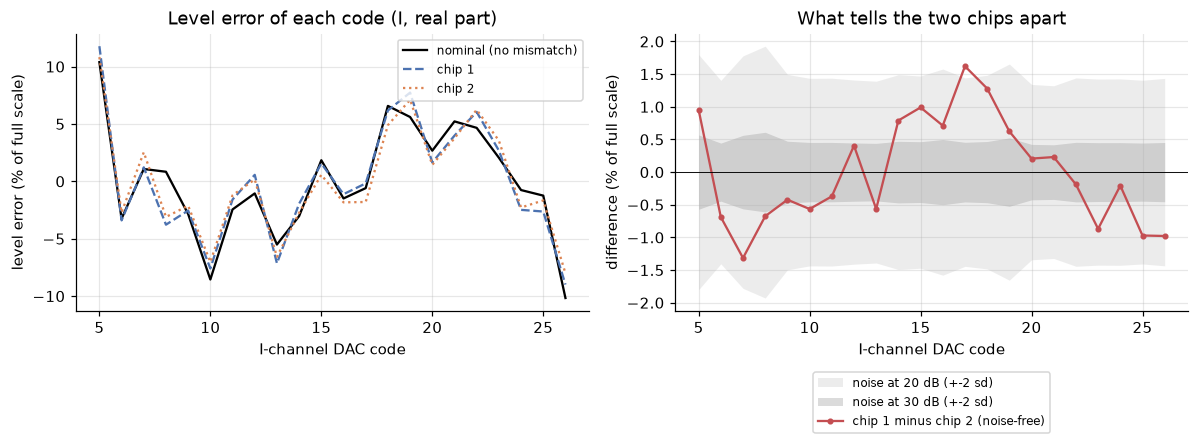

design curve (nominal): 4.7e-02 rms;  shift shared by both chips: 2.3e-02;  chip 1 vs chip 2: 6.6e-03
at 30 dB the diagonal noise-scaled distance is 26 (over all 88 numbers)
at 20 dB the diagonal noise-scaled distance is 8 (over all 88 numbers)


In [5]:
# Fingerprint = deviation of each code's level from a straight line (same definition as sim/live_demo.py)
ci, cq = np.array(live["ci"]), np.array(live["cq"]); lo, hi = live["codes"][0], live["codes"][-1]
codes = np.arange(lo, hi + 1); n = len(codes)
def ladder(y, ci, cq):
    A = np.concatenate([np.eye(n)[ci - lo], np.eye(n)[cq - lo][:, 1:]], 1)      # one level per I code and per Q code
    w = np.linalg.lstsq(A, y, rcond=None)[0]
    li, lq, k = w[:n], np.concatenate([[0], w[n:]]), np.arange(n)
    return np.concatenate([v - np.polyval(np.polyfit(k, v, 1), k) for v in (li.real, li.imag, lq.real, lq.imag)])
def baseband(d):
    return {c: np.array(v["baseband"][0]) + 1j * np.array(v["baseband"][1]) for c, v in d["chips"].items()}
y = baseband(live)
fp = {c: ladder(y[c], ci, cq) for c in y}

# receiver noise: spread of the fingerprint measured from one received burst of 18 noisy frames, as in the main
# study. The receiver compares that burst with a template averaged over 40 enrolment bursts, so the noise on the
# comparison is essentially that of the one burst.
def noise_sd(snr, trials=300, R=18):
    rng = np.random.default_rng(0); CI, CQ = np.tile(ci, R), np.tile(cq, R)
    s = np.sqrt(np.mean(np.abs(y["nominal"]) ** 2) / 10 ** (snr / 10) / 2)
    z = [ladder(np.tile(y["nominal"], R) + s * (rng.standard_normal(R * len(ci)) + 1j * rng.standard_normal(R * len(ci))), CI, CQ)
         for _ in range(trials)]
    return np.std(z, 0)
sd = {snr: noise_sd(snr) for snr in (30, 20)}
d12 = fp["1"] - fp["2"]
rms = lambda v: np.sqrt(np.mean(v ** 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for c, col, ls in (("nominal", "k", "-"), ("1", C["base"], "--"), ("2", C["comp"], ":")):
    ax[0].plot(codes, 100 * fp[c][:n], ls, color=col, label="nominal (no mismatch)" if c == "nominal" else f"chip {c}")
ax[0].set(xlabel="I-channel DAC code", ylabel="level error (% of full scale)", title="Level error of each code (I, real part)")
ax[0].legend(fontsize=8)
for snr, a in ((20, 0.18), (30, 0.35)):
    band = 2 * sd[snr][:n]
    ax[1].fill_between(codes, -100 * band, 100 * band, color=C["grey"], alpha=a, lw=0, label=f"noise at {snr} dB (+-2 sd)")
ax[1].plot(codes, 100 * d12[:n], "o-", ms=3, color=C["bad"], label="chip 1 minus chip 2 (noise-free)")
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set(xlabel="I-channel DAC code", ylabel="difference (% of full scale)", title="What tells the two chips apart")
ax[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.20))
plt.tight_layout(); plt.show()

print(f"design curve (nominal): {rms(fp['nominal']):.1e} rms;  shift shared by both chips: "
      f"{rms((fp['1'] + fp['2']) / 2 - fp['nominal']):.1e};  chip 1 vs chip 2: {rms(d12):.1e}")
for snr in (30, 20):
    print(f"at {snr} dB the diagonal noise-scaled distance is {np.sqrt(np.sum((d12 / sd[snr]) ** 2)):.0f} "
          f"(over all {len(d12)} numbers)")
if RUN_LIVE:
    nom_diff = np.max(np.abs(fp["nominal"] - ladder(baseband(ref)["nominal"], ci, cq)))
    r12 = rms(ladder(baseband(ref)["1"], ci, cq) - ladder(baseband(ref)["2"], ci, cq))
    print(f"check against our run: nominal chip differs by {nom_diff:.1e} (should be ~0); chip-to-chip difference "
          f"{rms(d12):.1e} vs ours {r12:.1e} (same size expected; identical only on macOS)")
    if not np.isfinite(nom_diff) or nom_diff > 1e-5:
        raise AssertionError("nominal simulation does not match the reference; inspect live_run/*.log")
    if not np.all(np.isfinite(d12)) or rms(d12) <= 1e-6:
        raise AssertionError("live simulation did not produce distinct, finite chip fingerprints")

**What this shows.** The left plot is dominated by the **design's own curve**: the PA's compression, and the way each
code's level depends on the codes around it in this frame. It is jagged, but it is not noise (these are noise-free
simulations), and the mismatch-free simulation predicts it. Two things are left over:

* Both chips sit away from the nominal curve by roughly the same amount and in the same direction. Mismatch shifts the
  *average* chip, so the mismatch-free simulation does not predict the average chip exactly. This shared part cannot tell
  chips apart.
* What does tell them apart (right plot) is small, up to about 1.6% of full scale in the displayed I-real component
  (0.7% rms over all 88 features). Scaling each feature difference by its noise standard deviation gives a combined
  diagonal distance of about 26 at 30 dB and 8 at 20 dB. The features are correlated, so this illustrative distance is
  not a count of independent noise units or a significance level. Identification performance is measured separately
  in Result 1.

That chip-to-chip difference is the fingerprint. It comes from device mismatch in the PDK's Monte Carlo models,
including transistors and passives, and it is also why the receiver compares chips with each other's enrolled templates rather than
with the nominal design. The rest of the notebook asks where the fingerprint comes from, how a designer can change it,
and what makes it drift.

## 3. Result 1: chips of one design can be told apart

The first question is simply whether the fingerprint is large enough to identify chips. Below, accuracy for 16, 32 and
64 virtual chips at four SNRs, and the **authentication** view: can the receiver reject an *impostor*, a chip of the
same design that was never enrolled?

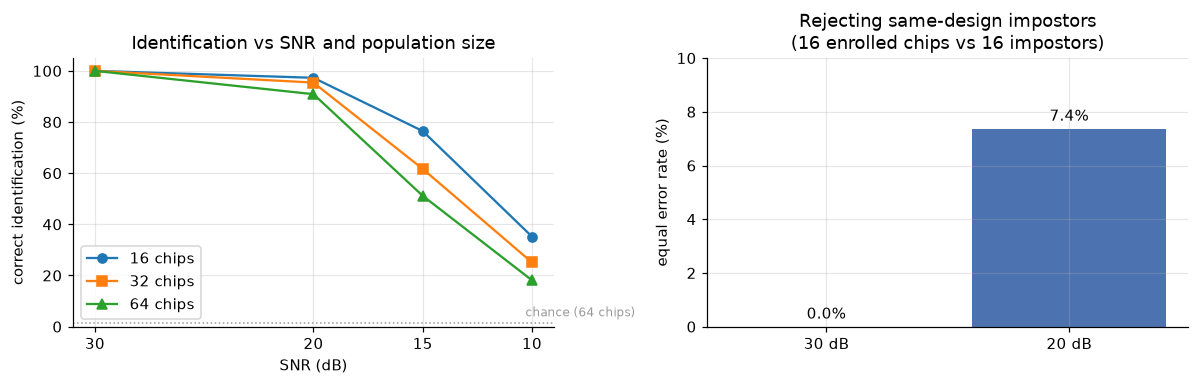

In [6]:
mc = load("tx_more_chips"); au = load("tx_auth")
snrs = [30, 20, 15, 10]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for n, mk in (("16", "o"), ("32", "s"), ("64", "^")):
    ax[0].plot(snrs, [100 * mc[n][f"{s}dB"] for s in snrs], marker=mk, label=f"{n} chips")
ax[0].axhline(100 / 64, color=C["grey"], ls=":", lw=1); ax[0].text(10.3, 4, "chance (64 chips)", fontsize=8, color=C["grey"])
ax[0].set(xlabel="SNR (dB)", ylabel="correct identification (%)", title="Identification vs SNR and population size",
          ylim=(0, 105)); ax[0].set_xticks(snrs); ax[0].invert_xaxis(); ax[0].legend()
labels = ["30 dB", "20 dB"]
eer = [100 * au["30dB"]["180_BASE"], 100 * au["20dB"]["180_BASE"]]
ax[1].bar(labels, eer, color=C["base"])
for i, v in enumerate(eer): ax[1].text(i, v + 0.3, f"{v:.1f}%", ha="center")
ax[1].set(ylabel="equal error rate (%)", title="Rejecting same-design impostors\n(16 enrolled chips vs 16 impostors)", ylim=(0, 10))
plt.tight_layout(); plt.show()

**What this shows.** With a good link (30 dB) every chip is identified correctly, even among 64 chips of the same design,
and the measured impostor EER is 0%. At 20 dB, accuracy drops to 91% for 64 chips and impostor EER rises to 7.37%.
At 10 dB, identification is only 18-35% across these population sizes. The fingerprint is real and usable, but it is
small: it needs a decent SNR.

Each point rests on a finite number of decisions: 480 for 16 chips and 1,920 for 64 chips (10 test bursts per chip,
3 noise seeds). The 95% intervals are 99.2-100% for 16 chips at 30 dB, 95.4-98.4% at 20 dB, 99.8-100% for 64 chips at
30 dB and 89.5-92.1% at 20 dB. These intervals cover the receiver noise only: the chips themselves are one fixed set
of Monte Carlo draws.

**How much averaging does this need?** *(Post hoc: added after a review pass asked for it.)* The plot below
reruns exactly the same analysis with 1 to 18 frames per burst; the 18-frame points reproduce the numbers above.

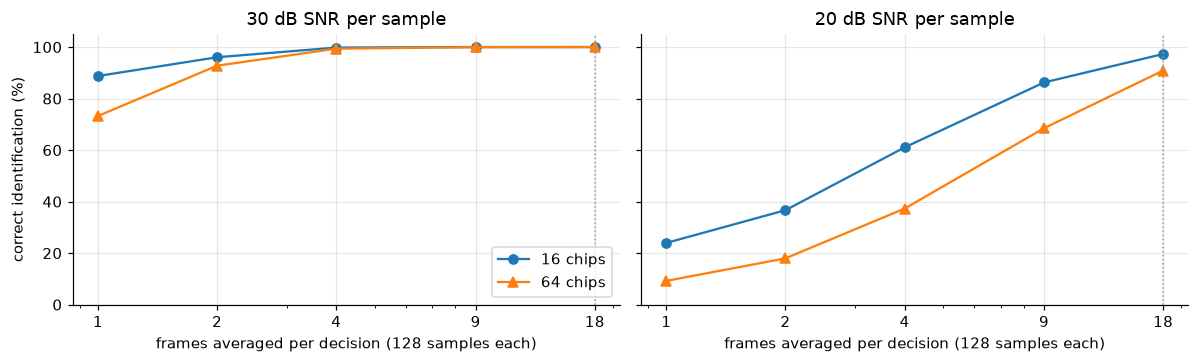

In [7]:
bl = load("tx_burst_length")["frames_per_burst"]; R = sorted(bl, key=int)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, snr in zip(ax, ("30dB", "20dB")):
    for n, mk in (("16", "o"), ("64", "^")):
        a.plot([int(r) for r in R], [100 * bl[r][n][snr] for r in R], marker=mk, label=f"{n} chips")
    a.set_xscale("log"); a.set_xticks([1, 2, 4, 9, 18], ["1", "2", "4", "9", "18"])
    a.set(xlabel="frames averaged per decision (128 samples each)", title=f"{snr[:-2]} dB SNR per sample", ylim=(0, 105))
    a.axvline(18, color=C["grey"], ls=":", lw=1)
ax[0].set_ylabel("correct identification (%)"); ax[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

**What this shows.** The fingerprint is strong enough to identify chips from a single 128-sample frame only on a good
link (89% for 16 chips at 30 dB), and the accuracy grows with averaging. A designer or receiver can trade observation
time for reliability: at 30 dB, 4 frames (20 us) already give 99%+; at 20 dB, 18 frames are needed for 91-97%. In a
real packet this is the length of known preamble the receiver must collect.

## 4. Result 2: where the fingerprint comes from

A transmitter has many imperfect blocks. To find which ones carry the fingerprint, we measured the chip-to-chip
pattern at several points along the chain in the same simulations (DAC currents, mixer output, PA output, final RF
output) and asked how much of the final fingerprint each stage already explains.

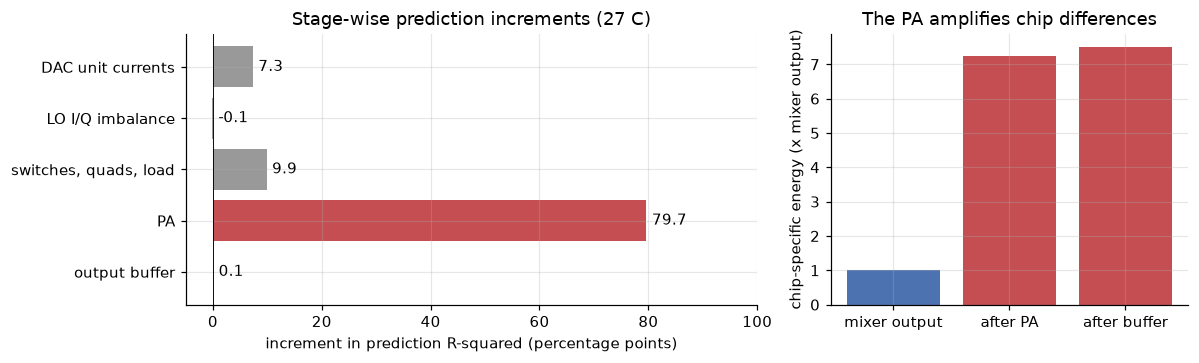

In [8]:
at = load("tx_attrib_aligned")["27"]["increments"]; sp = load("tx_split")["split"]
parts = {"DAC unit currents": at["DAC unit currents"], "LO I/Q imbalance": at["LO imbalance"],
         "switches, quads, load": at["switches/quads/load"], "PA": sp["PA increment"], "output buffer": sp["buffer increment"]}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].barh(list(parts)[::-1], [100 * v for v in list(parts.values())[::-1]],
           color=[C["bad"] if k == "PA" else C["grey"] for k in list(parts)[::-1]])
for i, v in enumerate(list(parts.values())[::-1]):
    ax[0].text(max(100 * v, 0) + 1, i, f"{100 * v:.1f}", va="center", ha="left")
ax[0].axvline(0, color="k", lw=0.6)
ax[0].set(xlabel="increment in prediction R-squared (percentage points)", title="Stage-wise prediction increments (27 C)", xlim=(-5, 100))
ax[1].bar(["mixer output", "after PA", "after buffer"], [1, sp["energy_pa_over_mix"], sp["energy_pa_over_mix"] * sp["energy_rf_over_pa"]],
          color=[C["base"], C["bad"], C["bad"]])
ax[1].set(ylabel="chip-specific energy (x mixer output)", title="The PA amplifies chip differences")
plt.tight_layout(); plt.show()

**What this shows.** The DAC and mixer mismatch is where the fingerprint *starts*. In the split-stage comparison,
predicting RF features from mixer features gives R-squared 0.203, while using PA features gives 0.999: a **79.7-point
increase**, with only 0.06 points left for the buffer. The left chart combines the DAC/LO/mixer attribution experiment
with the separate PA/buffer split experiment; these increments are not an additive partition totaling 100%. It also
retains the small negative LO increment (-0.09 points).

The right chart shows **energy**, which is squared feature magnitude: the PA-to-mixer ratio is 7.24x and the final
RF-to-mixer ratio is 7.50x. The corresponding feature-norm ratios are about 2.69x and 2.74x, not 7x amplitude gains.
LO quadrature errors contribute almost nothing in this analysis because the limiters square up the LO.

A later experiment refined this picture: the PA does not only amplify upstream mismatch, its own transistor mismatch is
a large part of the fingerprint too (Result 3). And a sensitivity study, re-running chips with the PDK's mismatch
scaled by 0.5x and 2x, suggests (from a simple fit we made after seeing the data) that about 70% of the fingerprint
comes from transistor mismatch and about 30% from resistor and capacitor mismatch, mostly in the PA loads.

This also explains a failure from early in the project: a fast "block-by-block" Python model of the transmitter, built
from separate block simulations, matched the real circuit only up to the mixer (correlation 0.9) and fell to 0.5 at
the RF output, because it treated the PA as a fixed curve rather than a source and amplifier of mismatch.

## 5. Result 3: design choices change the fingerprint

If the fingerprint has a mechanism, a designer should be able to move it. We made two variants of the transmitter and
simulated the same 16 chips (same random draws) in each, with predictions written down first:

* **Linear PA**: source degeneration in the PA. Prediction: the mixer-level fingerprint stays the same, the RF
  fingerprint shrinks below 0.7x.
* **Big DAC**: DAC transistors with 4x the area. Prediction (Pelgrom's law): mismatch halves at the mixer **and** at
  the RF output (0.35-0.65x).

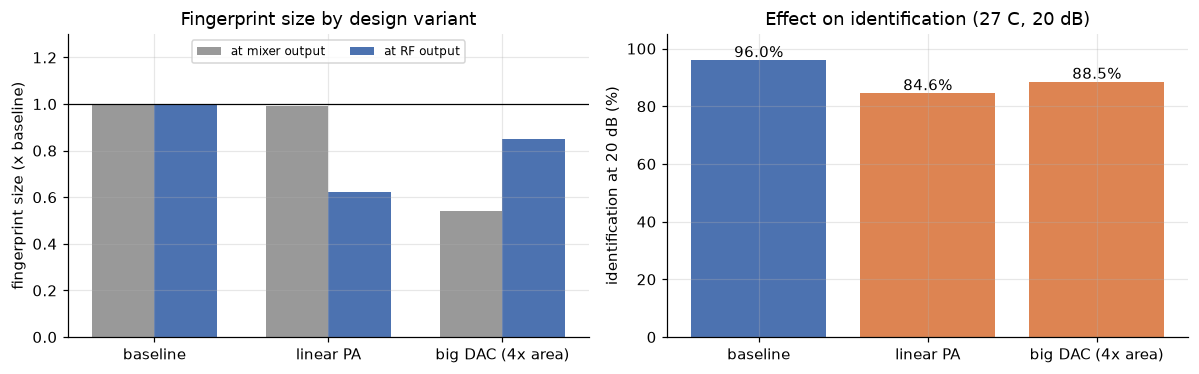

In [9]:
v = load("tx_variants_mc"); b = v["base"]
names = {"base": "baseline", "palin": "linear PA", "bigdac": "big DAC (4x area)"}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(3); w = 0.36
ax[0].bar(x - w / 2, [v[k]["S_mix"] / b["S_mix"] for k in names], w, label="at mixer output", color=C["grey"])
ax[0].bar(x + w / 2, [v[k]["S_rf"] / b["S_rf"] for k in names], w, label="at RF output", color=C["base"])
ax[0].set_xticks(x, list(names.values())); ax[0].axhline(1, color="k", lw=0.8)
ax[0].set(ylabel="fingerprint size (x baseline)", title="Fingerprint size by design variant", ylim=(0, 1.3))
ax[0].legend(loc="upper center", ncol=2, fontsize=8)
ax[1].bar(x, [100 * v[k]["acc_20dB"]["27"] for k in names], color=[C["base"], C["comp"], C["comp"]])
for i, k in enumerate(names): ax[1].text(i, 100 * v[k]["acc_20dB"]["27"] + 1, f"{100 * v[k]['acc_20dB']['27']:.1f}%", ha="center")
ax[1].set_xticks(x, list(names.values())); ax[1].set(ylim=(0, 105), ylabel="identification at 20 dB (%)", title="Effect on identification (27 C, 20 dB)")
plt.tight_layout(); plt.show()

**What this shows.**

* **Linear PA: prediction confirmed.** The mixer-level fingerprint is unchanged (0.99x) but the RF fingerprint drops
  to 0.62x, and identification at 20 dB falls from 96% to 85%. The PA is a **design lever**. Used in one direction it
  makes devices easier to authenticate; in the other it is an "anti-fingerprint" choice for privacy. It also lowered
  EVM from 11.4% to 6.1%.
* **Big DAC: prediction failed, informatively.** Mismatch at the mixer roughly halved, consistent with Pelgrom's scaling (0.54x), but
  the RF fingerprint only dropped to 0.85x. The PA's own mismatch dominates, so making the DAC better matched barely
  matters. We had underestimated the PA as a *source* of fingerprint, and this experiment is how we found out.

**Does this depend on the exact mismatch model?** We re-ran the key comparisons with the PDK's transistor mismatch
scaled by 0.5x and 2x. The linear-PA effect (0.64x at both scales) and the supply-versus-temperature ranking (Result 5)
held across that 4x range.

## 6. Result 4: the fingerprint survives the layout

Wiring adds capacitance everywhere, and every chip has the same wiring, so one might expect it to wash out the small
differences between chips. We extracted the parasitic capacitance of the transmitter core layout (before the regulator
was added) and re-ran the Monte Carlo identification on the extracted netlist. The final chip with the regulator was
extracted too and checked at nominal conditions: EVM 13.5% post-layout vs 14.0% in the schematic.

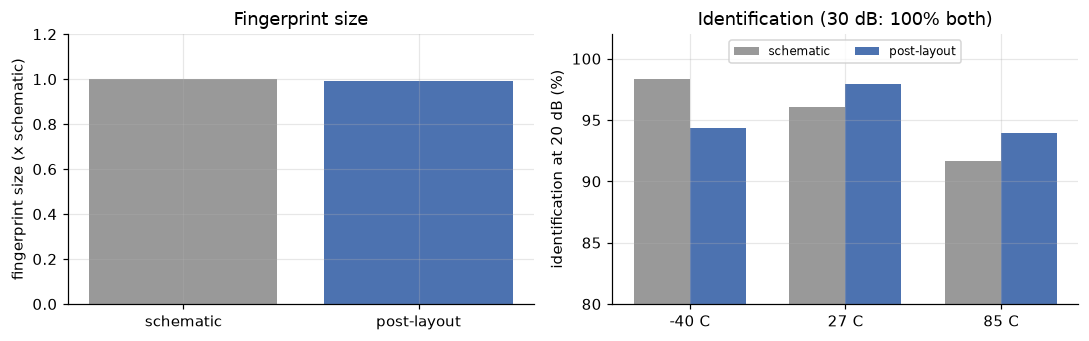

In [10]:
px = load("tx_pex")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(["schematic", "post-layout"], [1, px["verdict"]["S_rf post/schematic"]], color=[C["grey"], C["base"]])
ax[0].set(ylabel="fingerprint size (x schematic)", ylim=(0, 1.2), title="Fingerprint size")
T = ["-40", "27", "85"]; w = 0.36; xx = np.arange(3)
ax[1].bar(xx - w / 2, [100 * px["schematic"]["acc_20dB"][t] for t in T], w, label="schematic", color=C["grey"])
ax[1].bar(xx + w / 2, [100 * px["post-layout"]["acc_20dB"][t] for t in T], w, label="post-layout", color=C["base"])
ax[1].set_xticks(xx, [t + " C" for t in T]); ax[1].set(ylim=(80, 100), ylabel="identification at 20 dB (%)", title="Identification (30 dB: 100% both)")
ax[1].legend(loc="upper center", ncol=2, fontsize=8); ax[1].set_ylim(80, 102); plt.tight_layout(); plt.show()

**What this shows.** The fingerprint is essentially unchanged by the layout (0.99x its schematic size). At 30 dB
identification is 100% before and after extraction; at 20 dB it moves by a few points either way (from about -4 to
+2 points), which is within the variation we see between noise seeds and chip sets. A fingerprint predicted from the
schematic is a good guide to the laid-out chip. (The post-layout Monte Carlo draws follow the extracted netlist's
device order, so these are different random chips: the comparison is between populations.)

## 7. Result 5: what breaks the fingerprint, and design-time compensation

Real devices do not stay at room temperature and nominal supply. We enrolled every chip at 27 C and 1.80 V and then
tested it at other conditions.

**Temperature turned out to be a minor problem** for this design: from -40 C to 85 C identification stays at 100% at
30 dB (and 92-98% at 20 dB). **Supply voltage is the real threat.** Two parts of this setup favour that result: the LO
comes from outside the chip (in real devices, temperature hurts mostly through the on-board crystal's frequency drift,
Section 9), and the receiver sees a known, repeated frame.

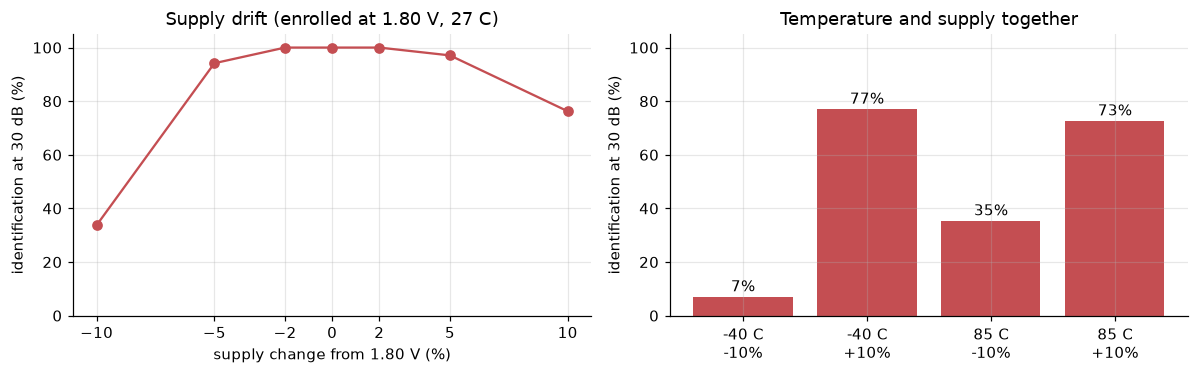

In [11]:
s = load("tx_supply")["30dB"]["BASE"]
vs = ["162", "171", "1764", "180", "1836", "189", "198"]; pct = [-10, -5, -2, 0, 2, 5, 10]
ts = load("tx_temp_supply")["30dB"]["BASE"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(pct, [100 * s[v] for v in vs], "o-", color=C["bad"])
ax[0].set(xlabel="supply change from 1.80 V (%)", ylabel="identification at 30 dB (%)", ylim=(0, 105),
          title="Supply drift (enrolled at 1.80 V, 27 C)"); ax[0].set_xticks(pct)
conds = ["-40C_162", "-40C_198", "85C_162", "85C_198"]; lab = ["-40 C\n-10%", "-40 C\n+10%", "85 C\n-10%", "85 C\n+10%"]
ax[1].bar(lab, [100 * ts[c] for c in conds], color=C["bad"])
for i, c in enumerate(conds): ax[1].text(i, 100 * ts[c] + 2, f"{100 * ts[c]:.0f}%", ha="center")
ax[1].set(ylim=(0, 105), ylabel="identification at 30 dB (%)", title="Temperature and supply together")
plt.tight_layout(); plt.show()

Within about +-2-5% of the nominal supply identification holds; at -10% it collapses to 34%, and cold plus low supply
gives just 7%. The drift moves **every** chip's fingerprint in a similar direction, which pushes them all towards the
wrong templates.

### Can design-time knowledge compensate?

Because the drift is largely shared, it can in principle be predicted. We simulated a separate set of chips at **wrong
process corners** (slow and fast), across supply and temperature, and learned from them how drift moves the fingerprint.
The receiver then scores each candidate chip over a grid of possible conditions (a Gaussian mixture), so it does not
need to know the supply or temperature. The 16 chips being tested are never used to learn the drift.

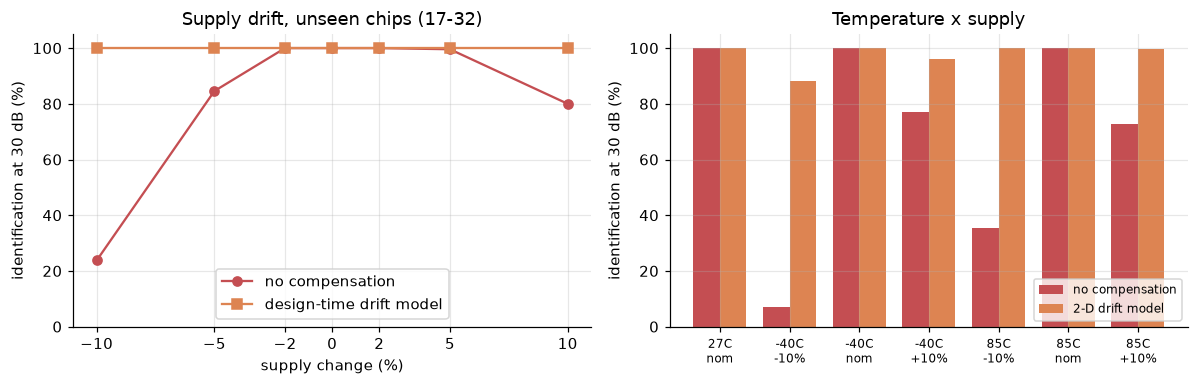

In [12]:
bv = load("tx_bv2")["30dB"]; t2 = load("tx_temp_supply")["30dB"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(pct, [100 * bv["BASE"][v] for v in vs], "o-", color=C["bad"], label="no compensation")
ax[0].plot(pct, [100 * bv["B"][v] for v in vs], "s-", color=C["comp"], label="design-time drift model")
ax[0].set(xlabel="supply change (%)", ylabel="identification at 30 dB (%)", ylim=(0, 105),
          title="Supply drift, unseen chips (17-32)"); ax[0].set_xticks(pct); ax[0].legend(loc="lower center")
conds = ["27C_180", "-40C_162", "-40C_180", "-40C_198", "85C_162", "85C_180", "85C_198"]
lab = ["27C\nnom", "-40C\n-10%", "-40C\nnom", "-40C\n+10%", "85C\n-10%", "85C\nnom", "85C\n+10%"]
xx = np.arange(len(conds)); w = 0.38
ax[1].bar(xx - w / 2, [100 * t2["BASE"][c] for c in conds], w, color=C["bad"], label="no compensation")
ax[1].bar(xx + w / 2, [100 * t2["B2D"][c] for c in conds], w, color=C["comp"], label="2-D drift model")
ax[1].set_xticks(xx, lab, fontsize=8); ax[1].set(ylim=(0, 105), ylabel="identification at 30 dB (%)", title="Temperature x supply")
ax[1].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

**What this shows.** At 30 dB the design-time drift model restores identification to 100% across +-10% supply on chips
it has never seen, at no cost at nominal conditions, and recovers 92% of the loss under combined temperature and supply
drift, where a simpler projection method failed. The record is honest but mixed: the method passed on two of three
chip sets and narrowly failed on the first (a 5-point drop at -2% supply), and at 20 dB it helps a lot but never meets
our strict "never worse anywhere" rule.

So receiver-side compensation works well but not perfectly. That led to the question behind the next result: can the
**transmitter** be designed so that the drift does not happen in the first place?

## 8. Result 6: fixing drift at the source with an on-chip regulator

Real radios do not run their analog circuits straight from a battery; they use a regulator. We designed one in SKY130
and put it on the chip:

* a **bandgap reference** built from vertical PNP transistors (1.213-1.217 V from -40 C to 85 C and 2.97-3.63 V input),
* an error amplifier and a **5 V PMOS pass device** that turn an external 3.3 V supply into the core's 1.8 V
  (+-0.4% over all temperatures and input voltages, about 1 ohm load regulation),
* on-chip decoupling, a **soft-start** and a **start-up guard**,
* all laid out (543 x 244 um): DRC-clean, strict LVS-clean, and start-up checked on the extracted layout
  (Section 1).

![LDO layout](images/ldo_zoom.png)

Then we repeated the drift tests with the regulator in front of the core, now varying the **external** supply.

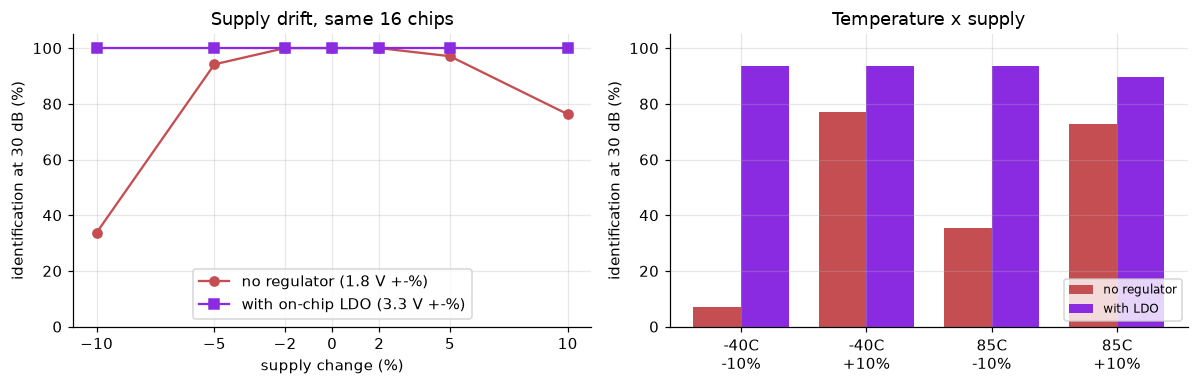

In [13]:
l1 = load("tx_ldo_L1")["30dB"]; l2 = load("tx_ldo_L2")["30dB"]; un = load("tx_supply")["30dB"]["BASE"]
vin = ["297", "3135", "3234", "330", "3366", "3465", "363"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(pct, [100 * un[v] for v in vs], "o-", color=C["bad"], label="no regulator (1.8 V +-%)")
ax[0].plot(pct, [100 * l1[v] for v in vin], "s-", color=C["ldo"], label="with on-chip LDO (3.3 V +-%)")
ax[0].set(xlabel="supply change (%)", ylabel="identification at 30 dB (%)", ylim=(0, 105), title="Supply drift, same 16 chips")
ax[0].set_xticks(pct)
ax[0].legend(loc="lower center")
pairs = [("-40C_162", "-40C_297", "-40C\n-10%"), ("-40C_198", "-40C_363", "-40C\n+10%"), ("85C_162", "85C_297", "85C\n-10%"),
         ("85C_198", "85C_363", "85C\n+10%")]
xx = np.arange(len(pairs)); w = 0.38
ax[1].bar(xx - w / 2, [100 * ts[a] for a, _, _ in pairs], w, color=C["bad"], label="no regulator")
ax[1].bar(xx + w / 2, [100 * l2[bk] for _, bk, _ in pairs], w, color=C["ldo"], label="with LDO")
ax[1].set_xticks(xx, [p[2] for p in pairs]); ax[1].set(ylim=(0, 105), ylabel="identification at 30 dB (%)", title="Temperature x supply")
ax[1].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

**What this shows.** With the regulator, identification stays at **100% across the whole +-10% supply range** at 30 dB
(96-98% at 20 dB), with no receiver-side compensation at all. Under combined temperature and supply drift it stays
between 88% and 94%, where the unregulated chip fell as low as 7% (the unregulated corner data come from a different
set of 16 chips, so that comparison is between populations, not chip by chip).

This is the main "by design" result of the project: **whether a fingerprint is stable is decided by an ordinary design
choice**, how the analog supply is generated, and it can be checked before tape-out.

## 9. What did not work

**Fingerprints on arbitrary data.** All results above use a known sequence, like a packet preamble, which is how most
practical RF fingerprinting works. When we enrolled chips on one data frame and tested them on different data, the
level-based identification accuracy fell to 8-14% (chance: 6.25% for 16 chips). Each code's measured level depends on
which other codes surround it, because the PA compresses the combined I/Q signal.

We then built a **model-based receiver** that learns how each chip turns data into a signal, and tested it with gates we
set in advance on fresh data frames. It passed at room conditions (93% at 30 dB on data it had never seen), but under
drift it collapsed (31-59%), and three design-time fixes we tried (fixed drift offsets, a learned drift subspace, and
amplitude-limited scoring) did not rescue it. A check showed why: under low supply each chip drifts in its own way (by 40% of
its fingerprint size at -10% supply, and by as much as the whole fingerprint when it is also cold), and that personal
drift could not be predicted from the chip's nominal fingerprint.

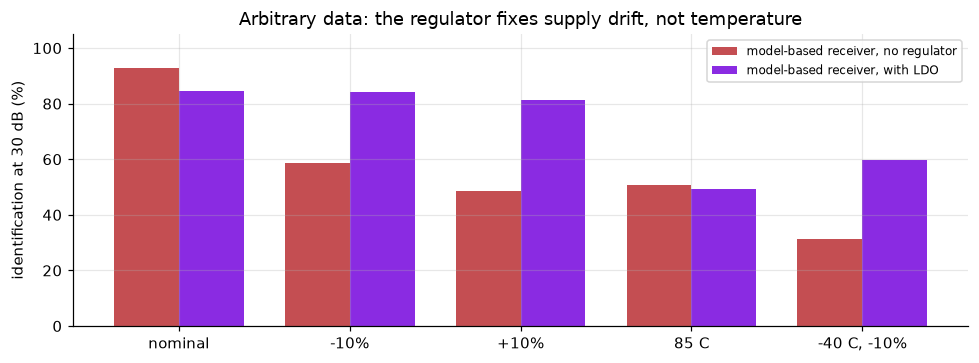

In [14]:
s3 = load("tx_modelrx_stage3")["30dB"]["MRX"]; l3 = load("tx_ldo_L3")["30dB"]
cm = [("27C_180", "27C_330", "nominal"), ("27C_162", "27C_297", "-10%"), ("27C_198", "27C_363", "+10%"),
      ("85C_180", "85C_330", "85 C"), ("-40C_162", "-40C_297", "-40 C, -10%")]
xx = np.arange(len(cm)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(xx - w / 2, [100 * s3[a] for a, _, _ in cm], w, color=C["bad"], label="model-based receiver, no regulator")
ax.bar(xx + w / 2, [100 * l3[b2] for _, b2, _ in cm], w, color=C["ldo"], label="model-based receiver, with LDO")
ax.set_xticks(xx, [c[2] for c in cm]); ax.set(ylim=(0, 105), ylabel="identification at 30 dB (%)",
                                              title="Arbitrary data: the regulator fixes supply drift, not temperature")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

With the regulator, supply drift is mostly fixed even for arbitrary data (-10%: 59% to 84%; +10%: 49% to 81%), but
**temperature** remains the limit (85 C: 50.6% without the regulator and 49.4% with it). The regulator also costs something
here: at nominal conditions the model-based receiver scores 84% with the LDO against 93% without it, so this test
failed its pre-registered gate overall. Identifying chips from arbitrary data while their temperature changes is the
open problem this project leaves.

**Other honest limits.**
* Everything is **simulation**. The only chip-to-chip randomness is the PDK's mismatch model; no silicon was measured.
  The sensitivity study (0.5x-2x mismatch) shows the conclusions are robust to the model being off by a constant factor,
  but not to it being wrong in kind.
* One base design (plus two variants). The mechanisms are likely general; the numbers are specific to this design.
* The receiver uses ideal downconversion; real receivers add their own impairments and frequency offset. In particular,
  measured studies on real devices find temperature hurts mostly through the **crystal oscillator's frequency drift**,
  which our design avoids by taking the LO from outside the chip.
* Regulator start-up was checked with parasitic capacitance but not wire resistance, at typical process and without
  mismatch; the worst peak (1.933 V) leaves only 17 mV of margin. Starting the *schematic* from exactly 0 V at 85 C
  still fails to converge in ngspice (the extracted layout starts normally in the same cases).
* Not yet a complete tape-out: the digital front end is a separate signed-off block, not yet wired to the analog core
  in one layout, and there are no pads or ESD protection.

## 10. Lessons for circuit designers

1. **The PA decides how big the fingerprint is.** Chip-specific energy is about 7.24x greater after the PA, which
   both shapes upstream mismatch and adds its own.
   Linearising the PA shrinks the fingerprint; that is an easy lever for privacy, and the reverse for authentication.
2. **Matching the DAC better barely matters** once the PA dominates. Spend area where the fingerprint is made.
3. **Supply, more than temperature, is the drift that breaks identification** in a design like this (external LO,
   known repeated frame).
   A regulated analog supply makes the fingerprint stable; check it in simulation before tape-out.
4. **Block-level models can mislead.** Our early behavioural model got the fingerprint right only up to the mixer and
   made temperature look like the main problem. Transistor-level simulation of the real layout changed the conclusions.
5. **Layout matters for the radio, not for the fingerprint.** Parasitics broke the I/Q balance (fixed by a small
   layout change) but left the fingerprint itself almost untouched.

## 11. Reproducing the results

The full project, with every script, layout generator and result file, is at
[github.com/byungkim113/Code-A-Chip](https://github.com/byungkim113/Code-A-Chip). The project log (`PLAN.md`) records
every pre-registration, result, bug and correction in order.

**Recommended tool versions** (the versions every result here was produced with):

| Tool | Version | Used for |
|---|---|---|
| SkyWater SKY130 PDK (open_pdks) | `c6d73a35f524070e85faff4a6a9eef49553ebc2b`, installed with volare 0.20.6 | all analog design, simulation and layout |
| ngspice | 47 (macOS); the live demo was also checked with 41 from conda-forge on x86 Linux | every transistor-level simulation |
| Magic | 8.3.684 | layout, DRC, extraction, device generation |
| Netgen | 1.5.324 | LVS |
| KLayout | 0.30.12, with the PDK's `sky130A_mr.drc` deck | second DRC, metal connectivity check |
| gLayout / gdsfactory / gdstk | 0.2.0 / 7.7.0 / 0.9.62 (1.0.2 in the notebook), in a separate Python 3.11 environment (the pinned layout packages fail to install on 3.12) | layout generation, reading the GDS |
| LibreLane | 3.0.16 (container image, with its pinned PDK `8afc8346a57fe1ab7934ba5a6056ea8b43078e71`: Yosys 0.62, OpenROAD 2026-02-17, Magic 8.3.623, Netgen 1.5.316, Icarus Verilog 13.0-devel) | digital front end |
| Python | 3.12.14 with numpy 2.5.3, scipy 1.18.1, scikit-learn 1.9.1, matplotlib 3.11.2 | analysis and this notebook |

Newer versions will very likely work. The PDK version matters most, because mismatch and device models change between
releases.

| Result | Script (in the repository) | Approximate ngspice time |
|---|---|---|
| Layout, DRC, LVS | `layout/tx_core.py`, `layout/check.sh`, `layout/klayout_drc.sh` | minutes |
| Parasitic extraction | `layout/pex.sh`, `sim/tx_pex.py`, `sim/pex_nominal_ldo.py` | ~1 h |
| Identification, temperature | `sim/tx_ident.py sim` then `analyze --masked` | ~5 h |
| Attribution (Result 2) | `sim/tx_attrib.py`, `sim/tx_split.py` | ~1 h |
| Design variants, sensitivity | `sim/tx_variant_mc.py`, `sim/tx_round2.py` | ~4 h each |
| Supply drift, design-time models | `sim/tx_supply.py`, `sim/tx_round2.py`, `sim/tx_round3.py` | ~6-12 h |
| On-chip LDO tests | `sim/ldo.py`, `sim/bandgap.py`, `sim/tx_round6.py` | ~24 h |
| Arbitrary-data receiver | `sim/tx_modelrx.py` | ~8 h |
| Live demo (Section 2b) | `notebook/setup_tools.sh`, `sim/live_demo.py` | ~4 min |
| Digital front end | `digital/src/tx_frontend.v`, `digital/tb/`, `digital/config.json` (LibreLane) | none (RTL sim seconds, flow ~10 min) |

Simulations are limited to two parallel ngspice processes; each process saves only the waveforms it needs and frees
them per chip (an early version without this used about 50 GB of RAM).

## Conclusion

Using only the open SKY130 PDK and open-source tools, we designed and verified a complete transmitter core and showed
that its RF fingerprint can be **predicted, explained and controlled before silicon exists**. Chips of one design are
reliably identifiable; the fingerprint is created by DAC and mixer mismatch and amplified by the PA; a linear PA shrinks
it; it survives layout parasitics; and its real weakness, supply drift, can be partly compensated with design-time
models and removed at the source by an on-chip regulator. The main open problem is identifying chips from arbitrary
data under temperature drift.

## Future work

* Measure fabricated chips to test the predictions made here (for example: identification at 30 dB, the +-5% supply
  tolerance without a regulator, and a 1.6x fingerprint reduction with a linear PA).
* Combine the regulator with a temperature-aware receiver for arbitrary data.
* Integrate the digital front end with the analog core in one layout and add a pad ring for tape-out.
* Repeat the study in a second open PDK (for example GF180 or IHP SG13G2) to separate general mechanisms from
  process-specific numbers.

## References

1. B. Chatterjee, D. Das, S. Sen, "RF-PUF: Enhancing IoT security through authentication of wireless nodes using in-situ
   machine learning," IEEE HOST 2018; IEEE Internet of Things Journal, 2019.
2. J. Xu, Y. Shen, E. Chen, V. Chen, "Bayesian neural networks for identification and classification of radio frequency
   transmitters using power amplifiers' nonlinearity signatures," IEEE Open Journal of Circuits and Systems, vol. 2, 2021.
3. "RF fingerprint classification with combinatorial-randomness-based power amplifiers and convolutional neural
   networks," IEEE, 2022 (IEEE Xplore 9950754); "Class-E power amplifiers incorporating fingerprint augmentation with
   combinatorial security primitives for machine-learning-based authentication in 65 nm CMOS," IEEE, 2022 (IEEE Xplore 9682436).
4. S. S. Hanna, D. Cabric, "Deep learning based transmitter identification using power amplifier nonlinearity,"
   arXiv:1811.04521.
5. "Characterizing and mitigating the effects of device temperature on RF fingerprinting accuracy," arXiv:2607.25070;
   "RF-TESI: Radio frequency fingerprint-based smartphone identification under temperature variation," ACM, 2023,
   doi:10.1145/3636462.
6. M. J. M. Pelgrom, A. C. J. Duinmaijer, A. P. G. Welbers, "Matching properties of MOS transistors," IEEE JSSC, vol. 24,
   no. 5, 1989.
7. SkyWater SKY130 open-source PDK; ngspice; Magic VLSI; Netgen; KLayout and the SKY130 KLayout DRC deck; gLayout;
   gdsfactory; volare.

## Acknowledgements

None.

## Appendix A: layout verification correction

Found on 2026-10-24 in a review of the verification by co-author Yucheng Wang, and fixed on 2026-10-25. The review
found that our layout check had passed a layout whose device sizes did not all match the design: Netgen reported
"match uniquely *with property errors*", and our script stopped reading after "match uniquely". Six devices differed:

| Device | Designed | Drawn | Cause | Fix |
|---|---|---|---|---|
| LDO soft-start capacitor | 70 x 70 um | 30 x 30 um | Magic's capacitor generator silently caps a plate at 30 um | 3 x 2 array of 28.6 um plates (4,908 um2) |
| PA and LO coupling capacitors (3) | 31 x 31 um | 30 x 30 um | same | design changed to the drawn 30 um (simulated effect: chip EVM 14.26% -> 14.22%, chip-to-chip fingerprint -0.8%) |
| Limiter feedback resistors (2) | 141 um | 139.4 um | the bends of a folded resistor are not full length | segments lengthened; now 141.0 um |
| Bias n-diffusion resistor | 80 um | 78.3 um | same | segments lengthened; now 79.98 um |

The small soft-start capacitor mattered: with it, the extracted regulator overshot to 2.13-2.38 V at power-up. After the
fix the layout passes strict LVS, including device sizes (a deliberately wrong capacitor size in the reference now
fails the check, as it should), and the extracted regulator meets the 1.95 V limit in all cases above. The LDO layout
also matches the exact netlist used in the simulations. The fingerprint results are unaffected: they were simulated
with the designed values, and the post-layout fingerprint check already used the drawn 30 um capacitors.